# Integrate two DLPFC slices

Use **all labelled spots from slices 151675 and 151676**, their released H&E features and **10 CPU epochs**. Coordinates stay in each slice's native frame. A block-diagonal graph prevents artificial spatial edges across slices while a shared model learns their representation.

Set `STAIG_DATA` to an unpacked `Dataset` directory or enable the on-demand download below. This is a bounded execution example, not the result reported in [paper Figure 5a](https://www.nature.com/articles/s41467-025-56276-0/figures/5).

In [1]:
import os
import warnings

# Compact warnings preserve their message without machine-specific source paths.
def show_warning(message, category, filename, lineno, file=None, line=None):
    print(f"{category.__name__}: {message}")
warnings.showwarning = show_warning

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import staig
from staig import datasets, img, metrics, pl, pp

torch.set_num_threads(min(4, os.cpu_count() or 1))
plt.rcParams.update({"figure.figsize": (4.5, 4), "figure.dpi": 85})
root = os.getenv("STAIG_DATA")  # Unpacked Dataset root; None uses ./Dataset.
device = "cpu"  # Deliberately avoids the shared GPU.
print({"staig": staig.__version__, "torch": torch.__version__, "device": device})

{'staig': '2.0.0', 'torch': '2.11.0+cu128', 'device': 'cpu'}


## Load and concatenate

Select HVGs per count slice, normalise once and use the HVG intersection. All inputs carry features in matching barcode order.

In [2]:
slice_ids = ["151675", "151676"]
slices = [datasets.load_dlpfc(s, root=root, download=True) for s in slice_ids]
adata = pp.concat_slices(slices, batch_key="slice", batch_categories=slice_ids,
                         n_top_genes=5000)
assert adata.n_obs == sum(s.n_obs for s in slices)
assert adata.obsm["image_features"].shape[0] == adata.n_obs
print(adata.obs["slice"].value_counts(sort=False).to_dict())
print(adata.uns["staig"]["concat"])

[staig] load_labels: dropped 26 unlabelled spots


[staig] load_labels: dropped 29 unlabelled spots


[staig] concat_slices: 2 slices, 6997 spots, 2300 common HVGs


{'151675': 3566, '151676': 3431}
{'batch_key': 'slice', 'slices': ['151675', '151676'], 'n_common_hvg': 2300, 'n_top_genes': 5000}


## Train a shared model

`preprocess=False` retains the concatenated input matrix. Keep refinement disabled for this integration example. If enabled, `run` forwards the slice key so refinement stays within each slice.

In [3]:
model = staig.run(adata, n_clusters=7, preset="integration", batch_key="slice",
                  preprocess=False, refine=False, epochs=10, device=device,
                  loss_chunk_size=256, seed=0, verbose=False)
assert adata.obsm["X_staig"].shape == (adata.n_obs, 64)
assert np.isfinite(adata.obsm["X_staig"]).all()
assert np.isfinite(model.history["loss"]).all()
assert len(model.history["loss"]) == model.config.epochs
assert adata.obs["staig_domain"].notna().all()
print({"spots": adata.n_obs, "genes": adata.n_vars,
       "input_features": adata.obsm["X_staig_input"].shape[1],
       "epochs": model.config.epochs,
       "edge_mode": adata.uns["staig"]["edge_removal"]["mode"],
       "negative_mask": adata.uns["staig"]["negatives"],
       "n_negatives": adata.uns["staig"]["n_negatives"]})
rows, cols = adata.obsp["spatial_connectivities"].nonzero()
batches = adata.obs["slice"].to_numpy()
assert np.all(batches[rows] == batches[cols])
assert adata.uns["staig"]["negatives"] == "batch"
print("No spatial edges cross slice boundaries.")

{'spots': 6997, 'genes': 33538, 'input_features': 2300, 'epochs': 10, 'edge_mode': 'image', 'negative_mask': 'batch', 'n_negatives': 'all'}
No spatial edges cross slice boundaries.


## Inspect each slice and evaluate mixing

Concatenation does not keep per-slice H&E display metadata; these panels use coordinates. 

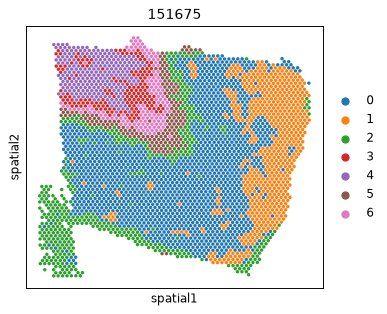

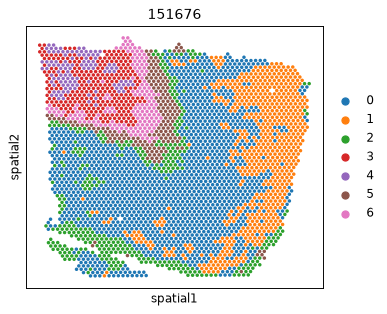

In [4]:
pl.spatial(adata, color="staig_domain", batch_key="slice")
plt.show()


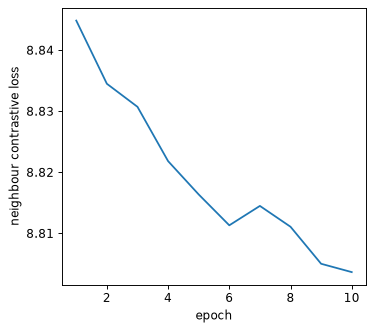

In [5]:
pl.loss_curve(adata)
plt.tight_layout()
plt.show()